ПРАКТИЧЕСКАЯ РАБОТА №6
КОРРЕЛЯЦИОННЫЙ АНАЛИЗ
Данные загружены
Всего сессий: 16923
Сессий с временем бронирования: 3993

1. КОРРЕЛЯЦИЯ ПИРСОНА


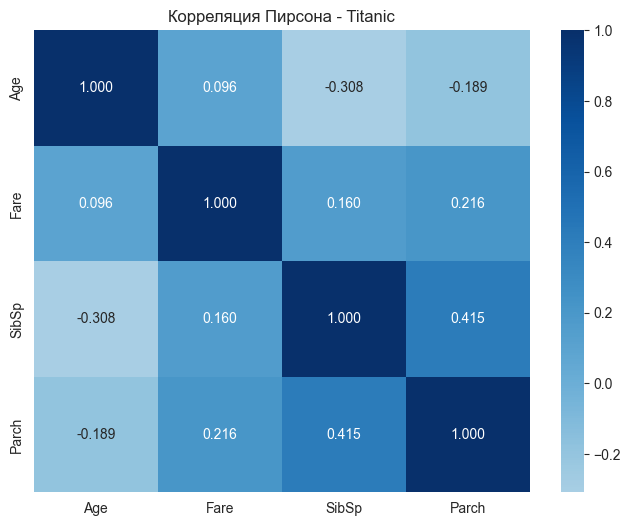

Возраст vs Цена билета: r=0.096, p=0.010216
  -> связь статистически значима (p < 0.05)

2. КОРРЕЛЯЦИЯ СПИРМЕНА


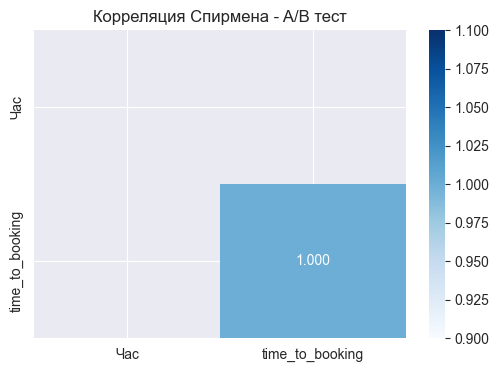

Час суток vs Время бронирования: r=nan, p=nan
  -> связь НЕ значима (p >= 0.05)

3. ХИ-КВАДРАТ


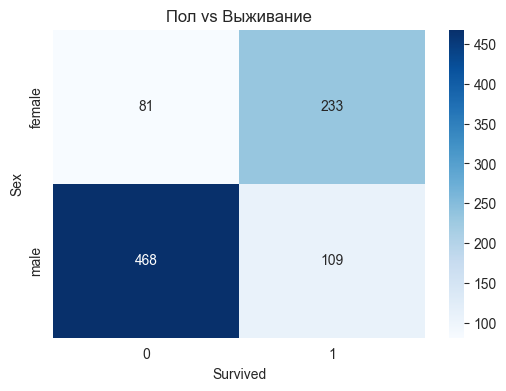

Хи-квадрат: χ²=260.7, p=0.000000
  -> связь статистически значима (p < 0.05)
  -> связь сильная

4. БИСЕРИАЛЬНАЯ КОРРЕЛЯЦИЯ
Ребенок vs Выживание: r=0.121, p=0.000278
  -> связь статистически значима (p < 0.05)


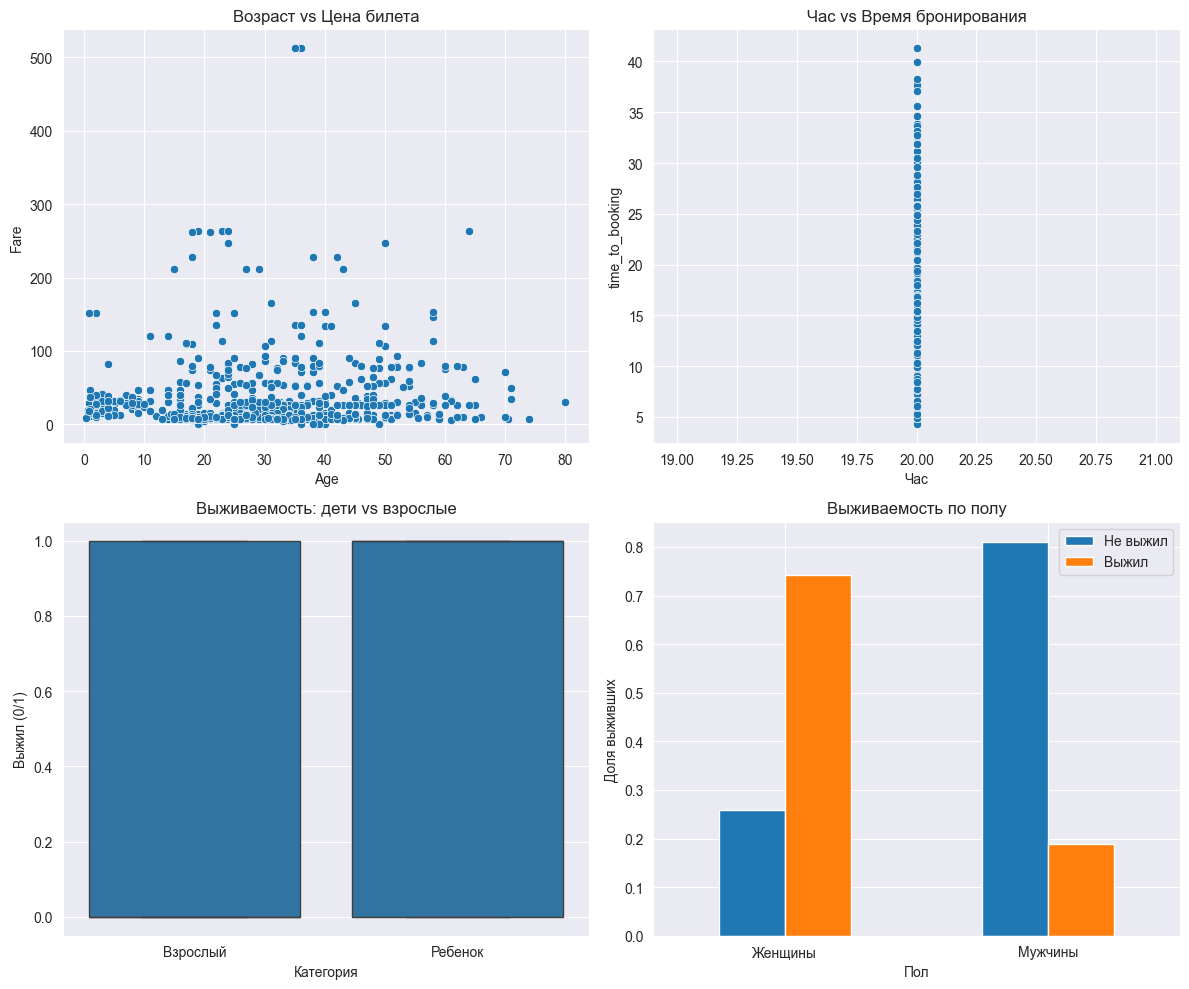


ИТОГОВЫЕ ВЫВОДЫ (α=0.05)
1. Возраст-Цена билета: r=0.096 (значима)
2. Час-Время бронирования: недостаточно данных для анализа
3. Пол-Выживание: χ²=260.7, сильная связь (p=0.000000)
4. Ребенок-Выживание: r=0.121 (значима)

ИНФОРМАЦИЯ О ДАННЫХ:
Пассажиров Titanic: 891
Из них детей (≤16 лет): 100
A/B сессий всего: 16923
A/B сессий с бронированием: 3993
Сессий с временем бронирования: 3993


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, chi2_contingency, pointbiserialr
import warnings
warnings.filterwarnings('ignore')

print("ПРАКТИЧЕСКАЯ РАБОТА №6")
print("КОРРЕЛЯЦИОННЫЙ АНАЛИЗ")
print("="*50)

# Загрузка данных
df_titanic = pd.read_csv("data/Titanic-Dataset.csv")
df_sessions = pd.read_csv("data/sessions_data.csv")
df_users = pd.read_csv("data/users_data.csv")

# Подготовка A/B данных
df_ab = df_sessions.merge(df_users, on='user_id', how='left')
df_ab['Бронирование'] = df_ab['booking_timestamp'].notna().astype(int)
df_ab['Час'] = df_ab['session_start_timestamp'].str[:2].astype(float)

print("Данные загружены")
print(f"Всего сессий: {len(df_ab)}")
print(f"Сессий с временем бронирования: {df_ab['time_to_booking'].notna().sum()}")

# 1. МАТРИЦА КОРРЕЛЯЦИЙ ПИРСОНА
print("\n1. КОРРЕЛЯЦИЯ ПИРСОНА")
numeric_cols = ['Age', 'Fare', 'SibSp', 'Parch']
corr_pearson = df_titanic[numeric_cols].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_pearson, annot=True, cmap='Blues', center=0, fmt='.3f')
plt.title('Корреляция Пирсона - Titanic')
plt.show()

# Проверка значимости (одинаковые индексы)
mask = df_titanic['Age'].notna() & df_titanic['Fare'].notna()
r_age_fare, p_age_fare = pearsonr(df_titanic.loc[mask, 'Age'], df_titanic.loc[mask, 'Fare'])
print(f"Возраст vs Цена билета: r={r_age_fare:.3f}, p={p_age_fare:.6f}")
if p_age_fare < 0.05:
    print("  -> связь статистически значима (p < 0.05)")
else:
    print("  -> связь НЕ значима (p >= 0.05)")

# 2. КОРРЕЛЯЦИЯ СПИРМЕНА
print("\n2. КОРРЕЛЯЦИЯ СПИРМЕНА")
ab_mask = df_ab['Час'].notna() & df_ab['time_to_booking'].notna()

if ab_mask.sum() > 0:
    corr_spearman = df_ab.loc[ab_mask, ['Час', 'time_to_booking']].corr(method='spearman')
    plt.figure(figsize=(6,4))
    sns.heatmap(corr_spearman, annot=True, cmap='Blues', fmt='.3f')
    plt.title('Корреляция Спирмена - A/B тест')
    plt.show()

    r_hour_time, p_hour_time = spearmanr(df_ab.loc[ab_mask, 'Час'], df_ab.loc[ab_mask, 'time_to_booking'])
    print(f"Час суток vs Время бронирования: r={r_hour_time:.3f}, p={p_hour_time:.6f}")
    if p_hour_time < 0.05:
        print("  -> связь статистически значима (p < 0.05)")
    else:
        print("  -> связь НЕ значима (p >= 0.05)")
else:
    print("Недостаточно данных для расчета корреляции Спирмена")
    r_hour_time = float('nan')
    p_hour_time = float('nan')

# 3. ХИ-КВАДРАТ (Пол vs Выживание)
print("\n3. ХИ-КВАДРАТ")
contingency = pd.crosstab(df_titanic['Sex'], df_titanic['Survived'])
plt.figure(figsize=(6,4))
sns.heatmap(contingency, annot=True, cmap='Blues', fmt='d')
plt.title('Пол vs Выживание')
plt.show()

chi2, p_chi, dof, _ = chi2_contingency(contingency)
print(f"Хи-квадрат: χ²={chi2:.1f}, p={p_chi:.6f}")
if p_chi < 0.05:
    print("  -> связь статистически значима (p < 0.05)")
    if chi2 > 10:
        print("  -> связь сильная")
    elif chi2 > 5:
        print("  -> связь средняя")
    else:
        print("  -> связь слабая")
else:
    print("  -> связь НЕ значима (p >= 0.05)")

# 4. БИСЕРИАЛЬНАЯ КОРРЕЛЯЦИЯ
print("\n4. БИСЕРИАЛЬНАЯ КОРРЕЛЯЦИЯ")
df_titanic['is_child'] = (df_titanic['Age'] <= 16).astype(int)
child_mask = df_titanic['is_child'].notna() & df_titanic['Survived'].notna()
r_biserial, p_biserial = pointbiserialr(df_titanic.loc[child_mask, 'is_child'],
                                        df_titanic.loc[child_mask, 'Survived'])
print(f"Ребенок vs Выживание: r={r_biserial:.3f}, p={p_biserial:.6f}")
if p_biserial < 0.05:
    print("  -> связь статистически значима (p < 0.05)")
else:
    print("  -> связь НЕ значима (p >= 0.05)")

# 5. ВИЗУАЛИЗАЦИЯ
fig, axes = plt.subplots(2, 2, figsize=(12,10))

# Scatter: Возраст vs Цена
sns.scatterplot(data=df_titanic[mask], x='Age', y='Fare', ax=axes[0,0])
axes[0,0].set_title('Возраст vs Цена билета')

# Scatter: Час vs Время бронирования
if ab_mask.sum() > 0:
    sns.scatterplot(data=df_ab[ab_mask], x='Час', y='time_to_booking', ax=axes[0,1])
    axes[0,1].set_title('Час vs Время бронирования')
else:
    axes[0,1].text(0.5, 0.5, 'Недостаточно данных', ha='center', va='center')
    axes[0,1].set_title('Час vs Время бронирования (нет данных)')

# Boxplot: Ребенок vs Выживание
sns.boxplot(data=df_titanic, x='is_child', y='Survived', ax=axes[1,0])
axes[1,0].set_xticklabels(['Взрослый', 'Ребенок'])
axes[1,0].set_title('Выживаемость: дети vs взрослые')
axes[1,0].set_xlabel('Категория')
axes[1,0].set_ylabel('Выжил (0/1)')

# Barplot: Выживаемость по полу
pd.crosstab(df_titanic['Sex'], df_titanic['Survived'], normalize='index').plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('Выживаемость по полу')
axes[1,1].set_xlabel('Пол')
axes[1,1].set_ylabel('Доля выживших')
axes[1,1].legend(['Не выжил', 'Выжил'])
axes[1,1].set_xticklabels(['Женщины', 'Мужчины'], rotation=0)

plt.tight_layout()
plt.show()

# ИТОГОВЫЕ ВЫВОДЫ
print("\n" + "="*70)
print("ИТОГОВЫЕ ВЫВОДЫ (α=0.05)")
print("="*70)

# Вывод 1
if p_age_fare < 0.05:
    sign1 = "значима"
else:
    sign1 = "не значима"
print(f"1. Возраст-Цена билета: r={r_age_fare:.3f} ({sign1})")

# Вывод 2
if not pd.isna(p_hour_time):
    if p_hour_time < 0.05:
        sign2 = "значима"
    else:
        sign2 = "не значима"
    print(f"2. Час-Время бронирования: r={r_hour_time:.3f} ({sign2})")
else:
    print("2. Час-Время бронирования: недостаточно данных для анализа")

# Вывод 3
if p_chi < 0.05:
    strength = "сильная" if chi2 > 10 else ("средняя" if chi2 > 5 else "слабая")
    print(f"3. Пол-Выживание: χ²={chi2:.1f}, {strength} связь (p={p_chi:.6f})")
else:
    print(f"3. Пол-Выживание: χ²={chi2:.1f}, связь не значима (p={p_chi:.6f})")

# Вывод 4
if p_biserial < 0.05:
    sign4 = "значима"
else:
    sign4 = "не значима"
print(f"4. Ребенок-Выживание: r={r_biserial:.3f} ({sign4})")

print("="*70)

# Дополнительная информация о данных
print("\nИНФОРМАЦИЯ О ДАННЫХ:")
print(f"Пассажиров Titanic: {len(df_titanic)}")
print(f"Из них детей (≤16 лет): {(df_titanic['Age'] <= 16).sum()}")
print(f"A/B сессий всего: {len(df_ab)}")
print(f"A/B сессий с бронированием: {df_ab['Бронирование'].sum()}")
print(f"Сессий с временем бронирования: {df_ab['time_to_booking'].notna().sum()}")